# Carbon Emissions Reporting Platform: Project Walkthrough
**Goal:** track Scope 1 and Scope 2 greenhouse-gas emissions of a steel plant, using the GHG Protocol.

This notebook walks through the project step by step: how the data is stored, how emissions are calculated, and how the analytics work. It runs the same backend code (`app.py`) that powers the dashboard.

**Core formula:** `Activity data × Emission factor = kgCO₂e`
(example: 100 litres of diesel × factor of diesel = emissions)

## 1. Setup

In [1]:
import os
os.environ["DB_PATH"] = "walkthrough.db"            # use a separate demo database
if os.path.exists("walkthrough.db"): os.remove("walkthrough.db")

import sqlite3, pandas as pd, matplotlib.pyplot as plt
import app                                          # our backend; on import it creates and fills the database
client = app.app.test_client()                      # lets us call the API without starting a server

def get(path):        return client.get(path).get_json()
def post(path, body): r = client.post(path, json=body); return r.status_code, r.get_json()

## 2. Database tables (master data)
The system is driven by 4 tables instead of hard-coded numbers:
- `emission_factors`: factor values with `valid_from` / `valid_to` dates (versioned)
- `emission_records`: every emission we calculate
- `audit_log`: history of manual overrides
- `business_metrics`: production and headcount, used for intensity

In [2]:
con = sqlite3.connect("walkthrough.db")
for t in ["emission_factors", "emission_records", "audit_log", "business_metrics"]:
    print(f"{t:20s}", con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0], "rows")

emission_factors     207 rows
emission_records     1656 rows
audit_log            0 rows
business_metrics     48 rows


## 3. Versioned emission factors
Each activity has several factor versions. The old ones are *expired* (`valid_to` is set); the current one has `valid_to = None`.

In [3]:
act = get("/api/meta")["activities"][0]             # pick the first activity as an example
print("Example activity:", act)
pd.DataFrame(get(f"/api/factors?scope={act['scope']}&activity={act['activity']}"))[
    ["valid_from", "valid_to", "kgco2e_per_unit", "unit", "source"]]

Example activity: {'activity': 'Acetylene', 'scope': 1, 'unit': 'kNm3'}


,valid_from,valid_to,kgco2e_per_unit,unit,source
0,2023-01-01,2023-12-31,3246.88,kNm3,SAMPLE prior revision (illustrative)
1,2024-01-01,2024-12-31,3122.00,kNm3,IPCC 2006 Guidelines
2,2025-01-01,None,3059.56,kNm3,SAMPLE current revision (illustrative)


## 4. Historical accuracy (most important feature)
The same quantity must give a **different result** depending on the *date of the activity*, because the factor valid on that date is used, not the latest one.

In [4]:
out = []
for d in ["2023-06-15", "2024-06-15", "2025-06-15"]:
    status, rec = post("/api/emissions", dict(scope=act["scope"], activity=act["activity"],
                                              quantity=100, activity_date=d, notes="walkthrough demo"))
    out.append(dict(activity_date=d, quantity=100, factor_used=rec["factor_used"], kgCO2e=rec["final_kgco2e"]))
pd.DataFrame(out)

,activity_date,quantity,factor_used,kgCO2e
0,2023-06-15,100,3246.88,324688.0
1,2024-06-15,100,3122.00,312200.0
2,2025-06-15,100,3059.56,305956.0


A date with **no valid factor** is rejected with a clear error instead of silently using a wrong factor:

In [5]:
post("/api/emissions", dict(scope=act["scope"], activity=act["activity"], quantity=100, activity_date="2020-06-15"))

(422,
 {'error': "No emission factor valid on 2020-06-15 for 'Acetylene' (scope 1)"})

## 5. Manual override with audit trail
A user can replace a calculated value, but a **reason is mandatory**, and the old and new values are saved in `audit_log`.

In [6]:
rid = rec["id"]
print("Without reason:", post(f"/api/emissions/{rid}/override", dict(value_kgco2e=1000, reason=""))[0], "(rejected)")
print("With reason:   ", post(f"/api/emissions/{rid}/override",
                              dict(value_kgco2e=1000, reason="Meter reading corrected", user="demo-user"))[0], "(accepted)")
pd.DataFrame(get(f"/api/audit-log?record_id={rid}"))[["record_id", "old_value", "new_value", "reason", "changed_by", "changed_at"]]

Without reason: 400 (rejected)
With reason:    200 (accepted)


,record_id,old_value,new_value,reason,changed_by,changed_at
0,1659,305956.0,1000.0,Meter reading corrected,demo-user,2026-10-17 17:44:24


## 6. Analytics
### 6.1 Year-over-year emissions by scope

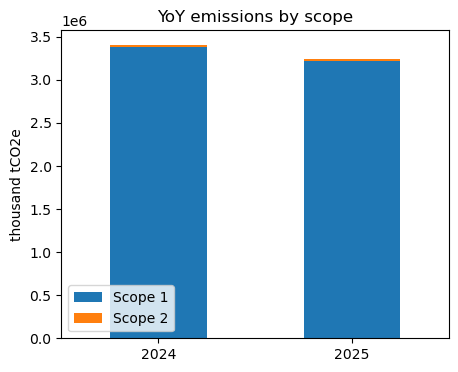

Total change vs previous year: -4.9%


In [7]:
y = get("/api/analytics/yoy?year=2025")
df = pd.DataFrame({"Scope 1": [y["previous"]["scope1"], y["current"]["scope1"]],
                   "Scope 2": [y["previous"]["scope2"], y["current"]["scope2"]]},
                  index=[y["previous_year"], y["year"]]) / 1e6        # kg -> thousand tonnes
df.plot(kind="bar", stacked=True, figsize=(5, 4), rot=0)
plt.ylabel("thousand tCO2e"); plt.title("YoY emissions by scope"); plt.show()
print(f"Total change vs previous year: {y['total_change_pct']:.1f}%")

### 6.2 Emission hotspots (which sources emit the most)

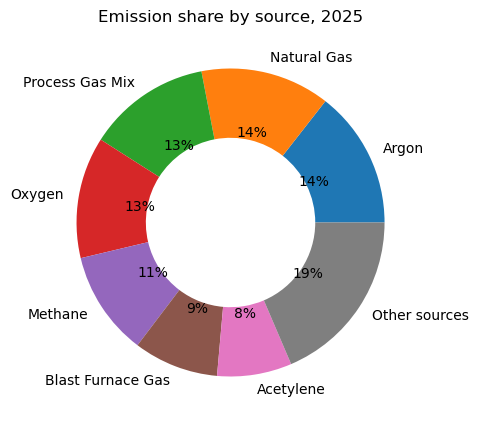

In [8]:
h = get("/api/analytics/hotspots?year=2025&top_n=7")["sources"]
plt.figure(figsize=(6, 5))
plt.pie([s["kg"] for s in h], labels=[s["activity"] for s in h], autopct="%1.0f%%", wedgeprops=dict(width=0.45))
plt.title("Emission share by source, 2025"); plt.show()

### 6.3 Emission intensity (emissions per tonne of steel)

In [9]:
i = get("/api/analytics/intensity?year=2025")
print(f"{i['total_kgco2e']:,.0f} kgCO2e  /  {i['metric_value']:,.0f} tonnes  =  {i['intensity']:,.0f} {i['intensity_unit']}")

3,239,034,840,478 kgCO2e  /  3,958,767 tonnes  =  818,193 kgCO2e per tonnes


### 6.4 Monthly trend

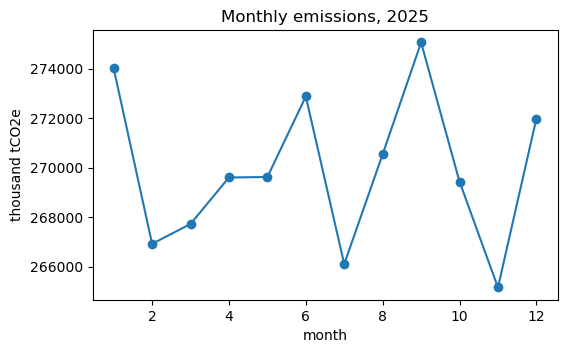

In [10]:
m = pd.DataFrame(get("/api/analytics/monthly?year=2025")["months"])
(m.set_index("month")["total"] / 1e6).plot(marker="o", figsize=(6, 3.5))
plt.ylabel("thousand tCO2e"); plt.title("Monthly emissions, 2025"); plt.show()

## 7. Data notes
- The Excel sheet has no year, so it is treated as **2024**. Missing months, all of 2025, the 2023/2025 factor versions and the business metrics are **generated sample data** (marked `SAMPLE` / `origin = 'sample'`).
- Some sheet factor units do not match the material units, and the quantities are very large, so absolute totals and intensity are not realistic. The sheet is used as given.

## 8. Summary
| Requirement | Where it is implemented |
|---|---|
| Versioned factors and business metrics | tables `emission_factors`, `business_metrics` |
| Historical accuracy | `find_factor()` in `app.py` |
| Override with audit trail | `/api/emissions/<id>/override` and table `audit_log` |
| YoY, intensity, hotspots | `/api/analytics/*` |
| Dashboard | `static/index.html` |